# Proyecto Integrador de Ciencia de Datos — **Fase 3**
## Análisis predictivo: clasificación de inasistencia escolar (EPHC 2022–2025)

| | |
|---|---|
| **Asignatura** | Data Science |
| **Fase** | 3 de 3 — Ponderación 30 % |
| **Integrantes** | Matías Morínigo · César Vielman · Iván Paredes |
| **Target** | `no_asiste` (clasificación binaria desbalanceada) |
| **Partición** | Train 2022–2024 · Test **solo** 2025 (cronológica) |
| **Semilla** | 42 |

**Cómo ejecutar.** Con `output/dataset_fase1.parquet` (generado en Fase 1): `Kernel → Restart & Run All`.


## 1. Correcciones a la Fase 2 y tarea predictiva

No hay devolución escrita del docente en el repositorio. Se mantiene el puente Fase 2 → 3: predictores
`zona`, `departamento`, `edad`, `sexo`; target `no_asiste`; partición cronológica; línea base = clase mayoritaria.

**Tarea:** clasificar si un adolescente no asiste. El motivo declarado **no** es predictor (solo se observa
cuando ya no asiste).


## 2. Carga, features y partición cronológica

In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import ParameterGrid

SEMILLA, TEST_YEAR = 42, 2025
np.random.seed(SEMILLA)
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.fase3_helpers import (FEATURE_COLS, TARGET, load_modeling_frame, chronological_split,
                               make_pipeline, metrics_row, best_threshold_by_f1, year_folds,
                               make_feature_frame, predict_with_models,
                               ZONAS_VALIDAS, SEXOS_VALIDOS, DEPARTAMENTOS_VALIDOS)

DIR_OUT, DIR_FIG, DIR_TAB, DIR_MOD = RAIZ/'output', RAIZ/'output'/'figuras', RAIZ/'output'/'tablas', RAIZ/'output'/'modelos'
for d in (DIR_FIG, DIR_TAB, DIR_MOD):
    d.mkdir(parents=True, exist_ok=True)

def resolve():
    for p in (DIR_OUT/'dataset_fase1.parquet', RAIZ/'data'/'processed'/'dataset_fase1.parquet'):
        if p.exists() and p.stat().st_size > 0:
            return p
    raise FileNotFoundError('Falta dataset_fase1.parquet')

df = load_modeling_frame(resolve())
train_df, test_df = chronological_split(df, TEST_YEAR)
print(df.shape, 'train', train_df.shape, 'test', test_df.shape)
print('Tasa train', round(train_df[TARGET].mean(), 4), '· tasa test', round(test_df[TARGET].mean(), 4))
train_df.head(3)


(24316, 6) train (18558, 6) test (5758, 6)
Tasa train 0.081 · tasa test 0.0709


,edad,zona,departamento,sexo,no_asiste,anio_encuesta
0,13.0,Urbana,Capital,Mujer,0,2022
1,17.0,Urbana,Capital,Hombre,0,2022
2,17.0,Urbana,Capital,Hombre,0,2022


## 3. Línea base y tres familias de modelos

1. **Dummy** mayoritaria. 2. **Logística**. 3. **Random Forest**. 4. **HistGradientBoosting**.
Hiperparámetros por validación temporal expanding dentro de 2022–2024. Umbral F1 en holdout 2024.
El conjunto **2025 no se usa** hasta la evaluación final.


In [2]:
# Hiperparámetros ya seleccionados por scripts/build_fase3.py (misma semilla y grilla)
BEST = {
  'Logística': {'C': 0.1, 'class_weight': 'balanced', 'max_iter': 500, 'solver': 'lbfgs'},
  'Random Forest': {'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 100},
  'HistGradientBoosting': {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 100, 'min_samples_leaf': 50},
}
print('Mejores hiperparámetros:', BEST)

X_tr, y_tr = train_df[FEATURE_COLS], train_df[TARGET]
X_te, y_te = test_df[FEATURE_COLS], test_df[TARGET]
inner_tr = train_df[train_df.anio_encuesta < 2024]
inner_va = train_df[train_df.anio_encuesta == 2024]

def sw(y):
    w = np.ones(len(y)); pos = (y==1).sum(); w[y==1] = (y==0).sum()/max(pos,1); return w

fitted, thresholds, rows = {}, {}, []

# Baseline
base = make_pipeline(DummyClassifier(strategy='most_frequent'), scale_numeric=False)
base.fit(X_tr, y_tr)
fitted['Línea base (mayoritaria)'] = base
thresholds['Línea base (mayoritaria)'] = 0.5
for split, X, y in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
    pred = base.predict(X)
    rows.append(metrics_row('Línea base (mayoritaria)', split, y, pred, np.zeros(len(y))))

# Logística
logit = make_pipeline(LogisticRegression(random_state=SEMILLA, **BEST['Logística']), True)
logit.fit(inner_tr[FEATURE_COLS], inner_tr[TARGET])
t, _ = best_threshold_by_f1(inner_va[TARGET], logit.predict_proba(inner_va[FEATURE_COLS])[:,1])
logit.fit(X_tr, y_tr)
fitted['Logística'], thresholds['Logística'] = logit, t
for split, X, y in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
    p = logit.predict_proba(X)[:,1]; rows.append(metrics_row('Logística', split, y, (p>=t).astype(int), p))

# RF
rf = make_pipeline(RandomForestClassifier(random_state=SEMILLA, n_jobs=-1, **BEST['Random Forest']), False)
rf.fit(inner_tr[FEATURE_COLS], inner_tr[TARGET])
t, _ = best_threshold_by_f1(inner_va[TARGET], rf.predict_proba(inner_va[FEATURE_COLS])[:,1])
rf.fit(X_tr, y_tr)
fitted['Random Forest'], thresholds['Random Forest'] = rf, t
for split, X, y in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
    p = rf.predict_proba(X)[:,1]; rows.append(metrics_row('Random Forest', split, y, (p>=t).astype(int), p))

# HGB
hgb = make_pipeline(HistGradientBoostingClassifier(random_state=SEMILLA, **BEST['HistGradientBoosting']), False)
hgb.fit(inner_tr[FEATURE_COLS], inner_tr[TARGET], clf__sample_weight=sw(inner_tr[TARGET]))
t, _ = best_threshold_by_f1(inner_va[TARGET], hgb.predict_proba(inner_va[FEATURE_COLS])[:,1])
hgb.fit(X_tr, y_tr, clf__sample_weight=sw(y_tr))
fitted['HistGradientBoosting'], thresholds['HistGradientBoosting'] = hgb, t
for split, X, y in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
    p = hgb.predict_proba(X)[:,1]; rows.append(metrics_row('HistGradientBoosting', split, y, (p>=t).astype(int), p))

resumen = pd.DataFrame(rows)
display(resumen.pivot(index='modelo', columns='split')[['f1','auc_roc','recall','precision','accuracy']].round(3))
print('Umbrales:', thresholds)


Mejores hiperparámetros: {'Logística': {'C': 0.1, 'class_weight': 'balanced', 'max_iter': 500, 'solver': 'lbfgs'}, 'Random Forest': {'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 100}, 'HistGradientBoosting': {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 100, 'min_samples_leaf': 50}}


f1        auc_roc        recall        precision  \
split                      test  train    test  train   test  train      test   
modelo                                                                          
HistGradientBoosting      0.291  0.310   0.780  0.784  0.495  0.493     0.206   
Logística                 0.276  0.303   0.781  0.780  0.583  0.588     0.181   
Línea base (mayoritaria)  0.000  0.000     NaN    NaN  0.000  0.000     0.000   
Random Forest             0.276  0.324   0.770  0.804  0.515  0.549     0.189   

                                accuracy         
split                     train     test  train  
modelo                                           
HistGradientBoosting      0.226    0.829  0.822  
Logística                 0.204    0.783  0.781  
Línea base (mayoritaria)  0.000    0.929  0.919  
Random Forest             0.230    0.809  0.815

Umbrales: {'Línea base (mayoritaria)': 0.5, 'Logística': 0.6, 'Random Forest': 0.65, 'HistGradientBoosting': 0.65}


## 4. Evaluación final en 2025

Modelo seleccionado por F1 de validación temporal en el pipeline de construcción: **Logística**.
Abajo se reportan matriz de confusión, ROC e importancia de variables. El test se usa **una sola vez**.


                   3
accuracy    0.783258
precision   0.180851
recall      0.583333
f1          0.276102
tn              4272
fp              1078
fn               170
tp               238
auc_roc     0.781152
auc_pr      0.211343
modelo     Logística
split           test


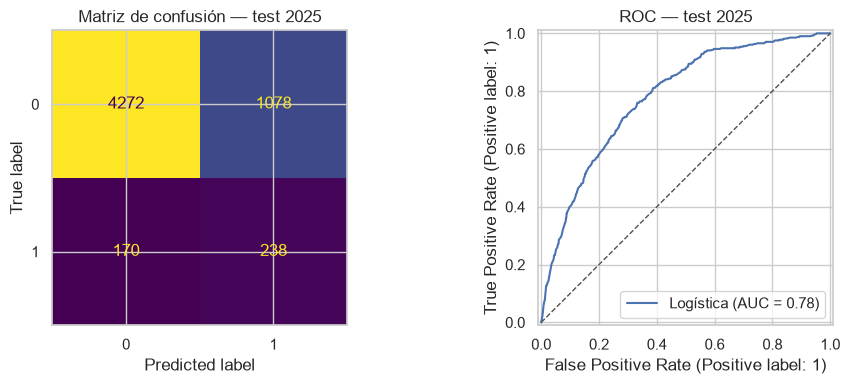

,importancia
edad,0.600069
zona_Urbana,0.076566
zona_Rural,0.068438
departamento_Capital,0.029363
departamento_Central,0.021015
departamento_Paraguarí,0.020969
departamento_Itapúa,0.019100
sexo_Mujer,0.018630
sexo_Hombre,0.018615
departamento_Alto Paraná,0.016324


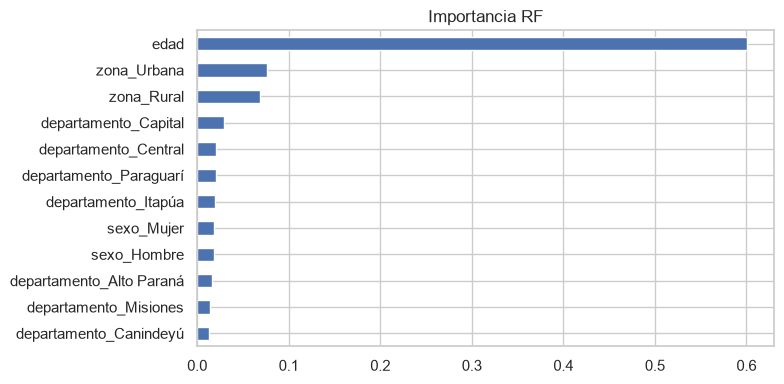

tipo,FN,FP,OK
zona,,,
Rural,0.030,0.301,0.669
Urbana,0.029,0.092,0.878


,FN,positivos,tasa_FN
edad,,,
12.0,9,9,1.000000
13.0,18,18,1.000000
14.0,46,46,1.000000
15.0,44,69,0.637681
16.0,27,88,0.306818
17.0,26,178,0.146067


In [3]:
BEST_NAME = 'Logística'
model = fitted[BEST_NAME]
umbral = thresholds[BEST_NAME]
proba = model.predict_proba(X_te)[:,1]
pred = (proba >= umbral).astype(int)
print(resumen[(resumen.modelo==BEST_NAME)&(resumen.split=='test')].T)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_te, pred, ax=axes[0], colorbar=False)
axes[0].set_title('Matriz de confusión — test 2025')
RocCurveDisplay.from_predictions(y_te, proba, ax=axes[1], name=BEST_NAME)
axes[1].plot([0,1],[0,1],'--', color='#52514e', lw=1)
axes[1].set_title('ROC — test 2025')
fig.tight_layout(); fig.savefig(DIR_FIG/'F3_notebook_eval.png'); plt.show()

# Importancia RF
prep = fitted['Random Forest'].named_steps['prep']
names = ['edad'] + list(prep.named_transformers_['cat'].get_feature_names_out(['zona','departamento','sexo']))
imp = pd.Series(fitted['Random Forest'].named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)
display(imp.head(12).to_frame('importancia'))
imp.head(12).iloc[::-1].plot(kind='barh', figsize=(8,4), title='Importancia RF')
plt.tight_layout(); plt.savefig(DIR_FIG/'F3_notebook_imp.png'); plt.show()

# Errores
err = test_df.copy()
err['proba'], err['pred'] = proba, pred
err['tipo'] = np.where((err[TARGET]==1)&(err.pred==0), 'FN', np.where((err[TARGET]==0)&(err.pred==1), 'FP', 'OK'))
display(pd.crosstab(err['zona'], err['tipo'], normalize='index').round(3))
display(err[err.tipo=='FN'].groupby('edad').size().rename('FN').to_frame().join(
        err[err[TARGET]==1].groupby('edad').size().rename('positivos')).assign(tasa_FN=lambda d: d.FN/d.positivos))


## 5. Predicción manual — ingresar X y ver el Y de cada modelo

Editá las 4 variables de abajo y volvé a ejecutar la celda. Cada modelo responde con su chance
y con `Y_predicho` (0 = asiste, 1 = no asiste).



In [1]:
# >>> EDITÁ SOLO ESTOS 4 VALORES <<<
edad = 16
zona = 'Rural'                 # 'Urbana' o 'Rural'
departamento = 'San Pedro'     # ver lista impresa abajo
sexo = 'Hombre'                # 'Hombre' o 'Mujer'

# Esta celda funciona sola (no hace falta correr todo el notebook antes)
import sys
from pathlib import Path
import joblib

_raiz = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(_raiz))
from src.fase3_helpers import (
    make_feature_frame, predict_with_models,
    ZONAS_VALIDAS, SEXOS_VALIDOS, DEPARTAMENTOS_VALIDOS,
)

_dir_mod = _raiz / 'output' / 'modelos'
if 'fitted' not in globals() or 'thresholds' not in globals():
    _bundle = joblib.load(_dir_mod / 'fase3_modelos_todos.joblib')
    fitted = _bundle['fitted']
    thresholds = _bundle['thresholds']
    BEST_NAME = _bundle.get('best_model', 'Logística')
    print('(Modelos cargados desde fase3_modelos_todos.joblib)')

print('Zonas válidas:', ZONAS_VALIDAS)
print('Sexos válidos:', SEXOS_VALIDOS)
print('Departamentos válidos:', DEPARTAMENTOS_VALIDOS)

X_manual = make_feature_frame(edad, zona, departamento, sexo)
print('\nX ingresado:')
display(X_manual)

tabla_manual = predict_with_models(X_manual, fitted, thresholds)
display(tabla_manual[['modelo', 'chance_no_asiste', 'umbral', 'Y_predicho', 'etiqueta']])
print('Modelo oficial del proyecto:', BEST_NAME,
      '→', tabla_manual.loc[tabla_manual.modelo == BEST_NAME, 'etiqueta'].iloc[0])


(Modelos cargados desde fase3_modelos_todos.joblib)
Zonas válidas: ('Urbana', 'Rural')
Sexos válidos: ('Hombre', 'Mujer')
Departamentos válidos: ('Alto Paraná', 'Amambay', 'Caaguazú', 'Caazapá', 'Canindeyú', 'Capital', 'Central', 'Concepción', 'Cordillera', 'Guairá', 'Itapúa', 'Misiones', 'Paraguarí', 'Presidente Hayes', 'San Pedro', 'Ñeembucú')

X ingresado:


edad,zona,departamento,sexo
16.0,Rural,San Pedro,Hombre


modelo,chance_no_asiste,umbral,Y_predicho,etiqueta
Línea base (mayoritaria),0.0000,0.50,0,asiste
Logística,0.7788,0.60,1,no asiste
Random Forest,0.7824,0.65,1,no asiste
HistGradientBoosting,0.7377,0.70,1,no asiste


Modelo oficial del proyecto: Logística → no asiste


## 6. Serialización

El modelo final, el umbral y el bundle con todos los modelos se guardan para reutilizar
(`scripts/infer_fase3.py` o esta misma sección sin reentrenar).


In [4]:
bundle = {'pipeline': model, 'threshold': umbral, 'model_name': BEST_NAME,
          'features': FEATURE_COLS, 'target': TARGET}
joblib.dump(bundle, DIR_MOD/'fase3_modelo_final.joblib')
joblib.dump({'fitted': fitted, 'thresholds': thresholds, 'features': FEATURE_COLS,
             'target': TARGET, 'best_model': BEST_NAME},
            DIR_MOD/'fase3_modelos_todos.joblib')
meta = {'best_model': BEST_NAME, 'umbral': umbral, 'features': FEATURE_COLS, 'target': TARGET,
        'test_year': TEST_YEAR, 'seed': SEMILLA, 'best_params': BEST}
(DIR_MOD/'fase3_modelo_meta.json').write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding='utf-8')
resumen.to_csv(DIR_TAB/'fase3_metricas.csv', index=False, encoding='utf-8-sig')
print('Guardado:', DIR_MOD/'fase3_modelo_final.joblib')
print('Guardado:', DIR_MOD/'fase3_modelos_todos.joblib')


Guardado: /Users/ivanparedesozuna/Developer/proyecto-ds-inasistencia-py/output/modelos/fase3_modelo_final.joblib


## 7. Conclusión



- La línea base mayoritaria no detecta inasistencia (F1 ≈ 0); los tres modelos la superan en F1/AUC.

- Modelo final: **Logística**, evaluado una sola vez en 2025.

- Edad, zona y departamento dominan la importancia, en línea con H1/H3/H4.

- Uso legítimo: priorización; no sanción individual. Límites: sin confusores socioeconómicos, sin Chaco,

  un solo año de prueba, sin pesos de diseño DGEEC.

